In [1]:
import pandas as pd
import numpy  as np

response  = pd.read_json("./responses.json")
questions = pd.read_json("./corpus_labeled_qs.json")

In [2]:
qst = response.data.map(lambda x: x['question'])
rsp = response.data.map(lambda x: x['response'])
qtp = questions.annotations.map(lambda x: x[0]["result"][0]["value"]["taxonomy"][0][-1])
act = response.annotations.map(lambda x: x[0]['result'][0]['value']['choices'][0])

In [3]:
# on vérifie qd meme que tout est ok
qqst = questions.data.map(lambda x: x['questions'])
qrsp = questions.data.map(lambda x: x['responses'])

assert (qqst == qst).all()
assert (qrsp == rsp).all()

In [4]:
data = pd.DataFrame()
data['question'] = qst
data['response'] = rsp
data['request_type'] = qtp.astype("category")
data['action'] = act.astype("category")

In [5]:
data[['response', 'action']].groupby("action", observed=False).count().sort_values(by="response", ascending=False)

,response
action,
MANUAL_ACTIVATION,122
CORRECTION,47
EXPLAIN_FAQ,34
HUMAN_TAKEOVER,31
REDIRECT_DEPOT,27
REJECT,6
ACTUAL_SEARCH,6
REDIRECT_POLICE_ETRANGERS,4
DELETE_LOCKED_ACCOUNT,4


In [6]:
data[['question', 'request_type']].groupby("request_type", observed=False).count().sort_values(by="question", ascending=False)

,question
request_type,
CONNECTION,78
CORRECTION_REQUEST,53
ACTIVATION,45
HOW_TO_SEARCH,42
DOCUMENT_NOT_FOUND,22
PRECISE_ADVANCED_RESEARCH,16
GENERAL,14
CLARIFY,11
FORGOTTEN_PASSWORD,6


Text(0, 0.5, '')

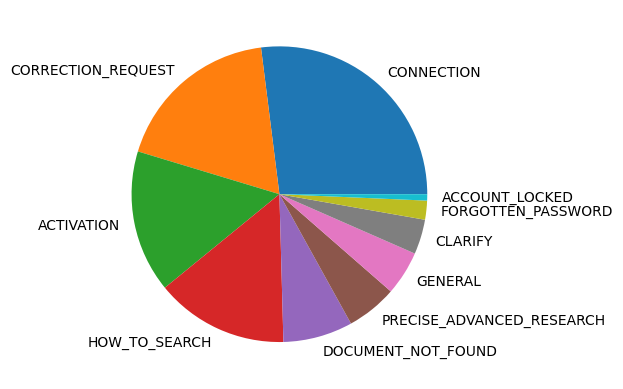

In [7]:
requests = data[['question', 'request_type']]
requests = requests.groupby("request_type", observed=False).count().sort_values(by="question", ascending=False)

#actions = actions[actions.index != 'MANUAL_ACTIVATION']

ax = requests.plot.pie(y="question", legend=None)
ax.set_ylabel("")

Text(0, 0.5, '')

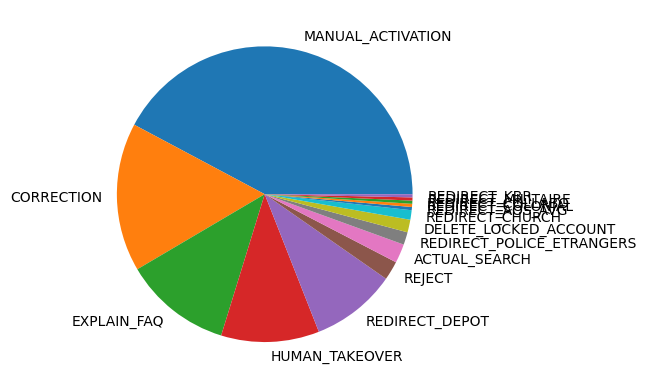

In [8]:
actions = data[['response', 'action']]
actions = actions.groupby("action", observed=False).count().sort_values(by="response", ascending=False)

#actions = actions[actions.index != 'MANUAL_ACTIVATION']

ax = actions.plot.pie(y="response", legend=None)
ax.set_ylabel("")

Text(0, 0.5, '')

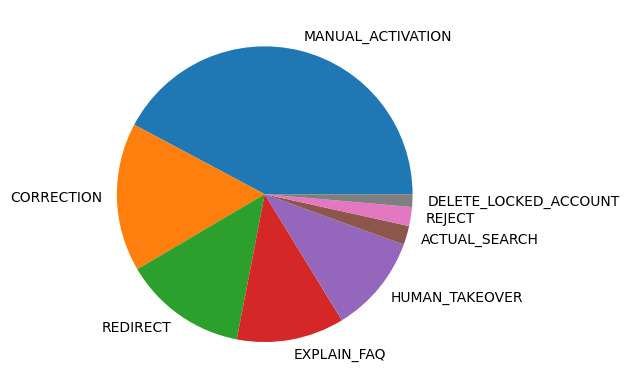

In [9]:
# simplify the above graph 
actions = data["action"].copy().map(lambda x: 'REDIRECT' if x.startswith("REDIRECT") else x)
actions = pd.DataFrame({"response": data["response"], "action": actions.astype("category")})

actions = actions.groupby("action", observed=False).count().sort_values(by="response", ascending=False)
#actions = actions[actions.index != 'MANUAL_ACTIVATION']

ax = actions.plot.pie(y="response", legend=None)
ax.set_ylabel("")

In [10]:
## dataset depuis lequel on va sampler des emails pour avoir un truc qui respect la structure générale
actions = data["action"].copy().map(lambda x: 'REDIRECT' if x.startswith("REDIRECT") else x)
corpus  = pd.DataFrame({"question": data["question"], "response": data["response"], "request_type": data["request_type"], "action": actions.astype("category")})

corpus.head()

,question,response,request_type,action
0,Van: communicat@arch.be <communicat@arch.be> \...,"Date: Wed, 03 Jul 2024 09:52:05 +0000\nTo: bar...",GENERAL,REJECT
1,De : communicat@arch.be <communicat@arch.be> \...,"Date: Fri, 05 Jul 2024 10:14:19 +0000\nTo: edm...",CONNECTION,EXPLAIN_FAQ
2,**Van:** loekspruit@gmail.com <loekspruit@gmai...,"Date: Wed, 10 Jul 2024 11:33:54 +0000\nTo: loe...",HOW_TO_SEARCH,REDIRECT
3,**De :** delphine kayaert <kayaertdelphine@gm...,"Date: Mon, 01 Jul 2024 13:44:22 +0000\nTo: ""de...",GENERAL,HUMAN_TAKEOVER
4,De : communicat@arch.be <communicat@arch.be> \...,"Date: Mon, 01 Jul 2024 14:33:17 +0000\nTo: ""Am...",HOW_TO_SEARCH,HUMAN_TAKEOVER


In [11]:
from langchain_ollama import OllamaEmbeddings

embed = OllamaEmbeddings(
    model    = "qwen3:8b",
    base_url = "http://localhost:11434",
)

computed = np.array(embed.embed_documents(list(corpus["question"])))
computed

array([[ 0.00300824, -0.00137867, -0.00030542, ..., -0.00070827,
         0.00884434,  0.00185667],
       [-0.00320879, -0.00869741, -0.00213601, ...,  0.0037854 ,
         0.00726348,  0.00341233],
       [ 0.01390952, -0.00204312, -0.00632124, ..., -0.00742327,
         0.00104962, -0.00324642],
       ...,
       [ 0.00617989,  0.00274027, -0.0093306 , ...,  0.00075442,
        -0.0027697 ,  0.00026006],
       [ 0.00509981,  0.00419379, -0.00330987, ..., -0.00895831,
         0.00204628, -0.01135368],
       [ 0.01452608,  0.00417096, -0.00546528, ...,  0.00258491,
         0.00143808, -0.00421059]], shape=(289, 4096))

In [12]:
computed = list(computed)

In [13]:
corpus["embedding"] = computed

In [14]:
corpus.to_parquet("corpus_clean.parquet")

In [18]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(
    corpus, 
    train_size   = 0.8,
    stratify     = corpus['action'],
    shuffle      = True,
    random_state = 42,
)

train, dev = train_test_split(
    train, 
    train_size   = 0.8, 
    stratify     = train['action'],
    shuffle      = True,
    random_state = 42,
)

In [19]:
print(f"TRAIN : {len(train)}")
print(f"DEV   : {len(dev)}")
print(f"TEST  : {len(test)}")

TRAIN : 184
DEV   : 47
TEST  : 58


In [20]:
train.to_parquet("train.parquet")
dev.to_parquet("dev.parquet")
test.to_parquet("test.parquet")

In [23]:
def plot(shard, title):
    x  = shard[['response', 'action']].groupby("action", observed=False).count().sort_values(by="response", ascending=False)
    ax = actions.plot.pie(y="response", legend=None)
    ax.set_title(title)
    ax.set_ylabel('')
    ax.plot()

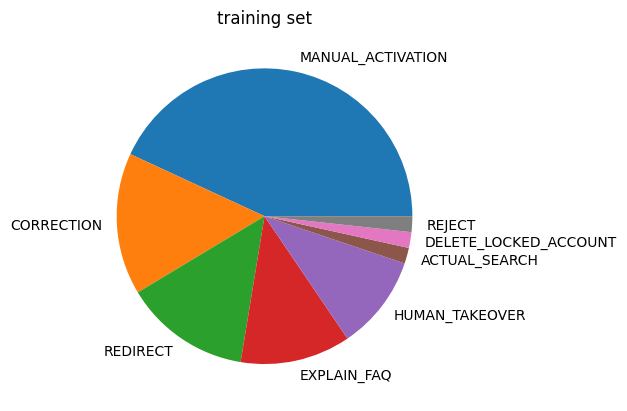

In [24]:
plot(train, "training set")

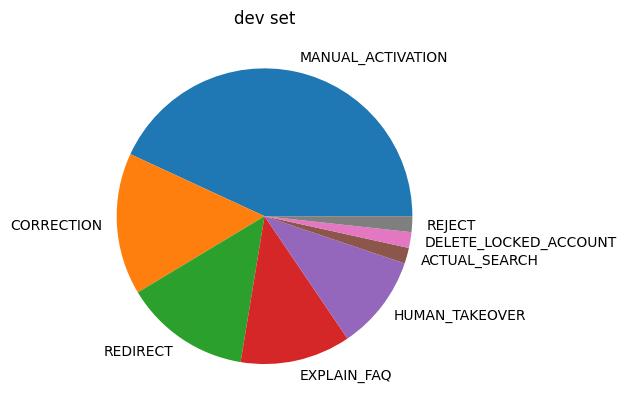

In [25]:
plot(dev, "dev set")

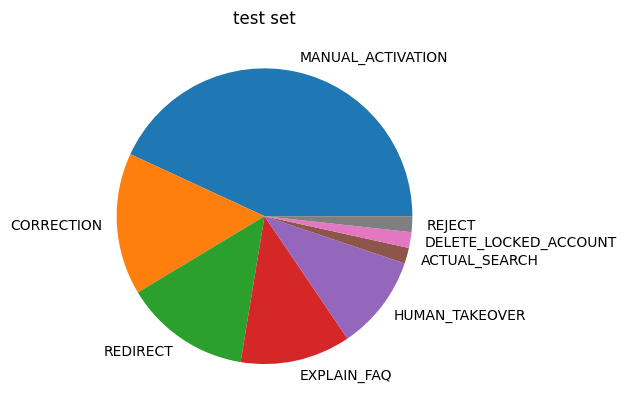

In [26]:
plot(test, "test set")

In [48]:
from sklearn.linear_model import LogisticRegression

X = np.stack(train["embedding"])
Y = np.argmax(pd.get_dummies(train["action"]), axis=1).astype(np.float32)

softmax = LogisticRegression(multi_class="multinomial", C=30)
softmax.fit(X, Y)

/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1264: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/home/xgillard/REPO/AGENTS/agr_agent/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,penalty,'l2'
,dual,False
,tol,0.0001
,C,30
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'multinomial'


In [40]:
X_dev = np.stack(dev["embedding"])
Y_dev = np.argmax(pd.get_dummies(dev["action"]), axis=1).astype(np.float32)

Y_pred= softmax.predict(X_dev)

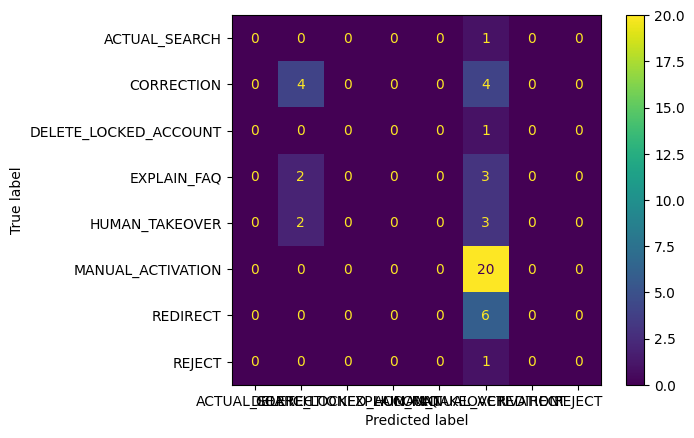

In [42]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(Y_dev, Y_pred)
